In [4]:
# Instal libraries
!pip install torch torchvision
!pip install roboflow

In [7]:
#Downloads a dataset from Roboflow in COCO format
!pip uninstall roboflow -y
!pip install roboflow==1.0.5
from roboflow import Roboflow
rf = Roboflow(api_key="csw3DwwqPe0hg7oFojEi")
project = rf.workspace("line-and-circle-detection").project("ancient-foundations")
version = project.version(1)
dataset = version.download("coco-segmentation")

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.3/155.3 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.7/178.7 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.8/67.8 kB 7.0 MB/s eta 0:00:00
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9655 sha256=cc647163964981b01a2dabc7dbfa0be36e15483dd4c341c8875634b5f33a3500
  Stored in directory: /root/.cache/pip/wheels/40/b3/0f/a40dbd1c6861731779f62cc4babcb234387e11d697df70ee97
Successfully built wget
  Attempting uninstall: pyparsing
    Found existing installation: pyparsing 3.2.3
    Uninstalling pyparsing-3.2.3:
      Successfully uninstalled pyparsing-3.2.3
  Attempting uninstall: idna
    Found existing installation: idna 3.7
    Uninstalling idna-3.7:
      Successfully uninstall

loading Roboflow workspace...
loading Roboflow project...


Extracting Dataset Version Zip to Ancient-Foundations-1 in coco-segmentation:: 100%|██████████| 304/304 [00:00<00:00, 612.03it/s]


In [ ]:
# Import necessary libraries
import os
import json
from PIL import Image, ImageDraw
from torch.utils.data import Dataset
import torchvision.transforms as T

# Custom dataset class for loading COCO polygon segmentation data
class CocoPolygonDataset(Dataset):
    def __init__(self, root, annotation_file, transforms=None):
        self.root = root
        self.transforms = transforms

        # Load the COCO annotation JSON file
        with open(annotation_file) as f:
            self.coco = json.load(f)

        # Create a dictionary to map image IDs to filenames
        self.image_id_to_filename = {img['id']: img['file_name'] for img in self.coco['images']}

        # Group annotations by image ID
        self.annotations_by_image = {}
        for ann in self.coco['annotations']:
            img_id = ann['image_id']
            if img_id not in self.annotations_by_image:
                self.annotations_by_image[img_id] = []
            self.annotations_by_image[img_id].append(ann)

        # Get a list of all image IDs
        self.image_ids = list(self.image_id_to_filename.keys())

    def __len__(self):
        # Return total number of images in the dataset
        return len(self.image_ids)

    def __getitem__(self, idx):
        # Get image ID and file path
        img_id = self.image_ids[idx]
        img_name = self.image_id_to_filename[img_id]
        img_path = os.path.join(self.root, img_name)

        # Load the image and convert to RGB
        image = Image.open(img_path).convert("RGB")

        # Create an empty (black) mask with same size as the image
        mask = Image.new('L', image.size, 0)

        # Draw white polygons on the mask using segmentation data
        if img_id in self.annotations_by_image:
            for ann in self.annotations_by_image[img_id]:
                if ann['iscrowd'] == 0:
                    for seg in ann['segmentation']:
                        polygon = [(seg[i], seg[i+1]) for i in range(0, len(seg), 2)]
                        ImageDraw.Draw(mask).polygon(polygon, outline=255, fill=255)

        # Apply image and mask transformations (convert to tensor and normalize)
        if self.transforms:
            image = self.transforms(image)
            mask = self.transforms(mask)

            # Convert mask to binary values (0 or 1)
            mask = (mask > 0.5).float()

        # Return image and mask
        return image, mask

# Define transformations to convert images to tensors
transforms = T.Compose([
    T.ToTensor(),
])

# Set dataset folder paths
dataset_root = "./Ancient-Foundations-1/train"
annotation_file = "./Ancient-Foundations-1/train/_annotations.coco.json"

# Create an instance of the dataset
train_dataset = CocoPolygonDataset(dataset_root, annotation_file, transforms=transforms)

# Load and test one image and its mask from the dataset
img, msk = train_dataset[0]
print(f"Image shape: {img.shape}, Mask shape: {msk.shape}")
print("Mask unique values:", msk.unique())

Image shape: torch.Size([3, 1024, 1024]), Mask shape: torch.Size([1, 1024, 1024])
Mask unique values: tensor([0., 1.])


In [ ]:
# Import required libraries for model training
import torch
from torch.utils.data import random_split, DataLoader
import torch.nn as nn
import torch.optim as optim
import torchvision
from tqdm import tqdm
from torch import amp
import os

# Use GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Split dataset into 80% training and 20% validation
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_subset, val_subset = random_split(train_dataset, [train_size, val_size])

# Create data loaders to load data in small batches
train_loader = DataLoader(train_subset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_subset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

# Load pretrained DeepLabv3 model with ResNet50 backbone
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights
weights = DeepLabV3_ResNet50_Weights.DEFAULT
model = deeplabv3_resnet50(weights=weights)

# Change model output to 1 channel for binary segmentation
model.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)
model = model.to(device)

# Define loss function (for binary classification with class imbalance)
pos_weight = torch.tensor([5.0]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Set optimizer and learning rate scheduler
optimizer = optim.Adam(model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1, verbose=True)

# Function to calculate IoU (intersection over union) score
def compute_iou(pred_mask, true_mask, threshold=0.5):
    pred_probs = torch.sigmoid(pred_mask)
    pred_bin = (pred_probs > threshold).float()
    true_mask = true_mask.float()
    intersection = (pred_bin * true_mask).sum(dim=(1,2,3))
    union = pred_bin.sum(dim=(1,2,3)) + true_mask.sum(dim=(1,2,3)) - intersection
    iou = (intersection + 1e-6) / (union + 1e-6)
    return iou.mean().item()

# Enable mixed precision training for faster performance on GPU
scaler = amp.GradScaler(enabled=torch.cuda.is_available())

# Set training parameters
num_epochs = 20
early_stop_patience = 3
best_val_loss = float('inf')
epochs_no_improve = 0
model_save_path = "./best_model_DeepLabv3+_20_Epochs.pth"

# Training loop
for epoch in range(num_epochs):
    model.train()  # Set model to training mode
    running_loss = 0.0
    train_iou = 0.0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} Training", leave=False)
    for images, masks in loop:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()  # Clear old gradients

        with amp.autocast(device_type='cuda' if torch.cuda.is_available() else 'cpu'):
            outputs = model(images)['out']
            loss = criterion(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        train_iou += compute_iou(outputs, masks) * images.size(0)

        loop.set_postfix(loss=loss.item(), iou=train_iou / (loop.n + 1e-6))

    # Calculate average training loss and IoU
    epoch_loss = running_loss / train_size
    epoch_iou = train_iou / train_size

    # Validation loop
    model.eval()  # Set model to evaluation mode
    val_loss = 0.0
    val_iou = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)
            outputs = model(images)['out']
            loss = criterion(outputs, masks)
            val_loss += loss.item() * images.size(0)
            val_iou += compute_iou(outputs, masks) * images.size(0)

    # Calculate average validation loss and IoU
    val_loss /= val_size
    val_iou /= val_size

    # Print training and validation performance
    print(f"Epoch [{epoch+1}/{num_epochs}] Train Loss: {epoch_loss:.4f}, Train IoU: {epoch_iou:.4f} | Val Loss: {val_loss:.4f}, Val IoU: {val_iou:.4f}")

    # Update learning rate if validation loss is not improving
    scheduler.step(val_loss)

    # Save model if validation loss is the best so far
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), model_save_path)
        print(f"Best model saved at epoch {epoch+1}")
    else:
        epochs_no_improve += 1
        # Stop training early if no improvement for several epochs
        if epochs_no_improve >= early_stop_patience:
            print(f"Early stopping triggered after {epoch+1} epochs")
            break

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth
100%|██████████| 161M/161M [00:00<00:00, 186MB/s]
The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.


Epoch [1/20] Train Loss: 0.4836, Train IoU: 0.5046 | Val Loss: 0.3174, Val IoU: 0.6308
Best model saved at epoch 1


Epoch [2/20] Train Loss: 0.2680, Train IoU: 0.6963 | Val Loss: 0.2417, Val IoU: 0.6951
Best model saved at epoch 2


Epoch [3/20] Train Loss: 0.1986, Train IoU: 0.7713 | Val Loss: 0.2098, Val IoU: 0.7260
Best model saved at epoch 3


Epoch [4/20] Train Loss: 0.1641, Train IoU: 0.7880 | Val Loss: 0.1936, Val IoU: 0.7030
Best model saved at epoch 4


...

Epoch [13/20] Train Loss: 0.0559, Train IoU: 0.8900 | Val Loss: 0.1245, Val IoU: 0.8026


Epoch [14/20] Train Loss: 0.0494, Train IoU: 0.9051 | Val Loss: 0.1013, Val IoU: 0.8170
Best model saved at epoch 14


Epoch [15/20] Train Loss: 0.0449, Train IoU: 0.9126 | Val Loss: 0.1052, Val IoU: 0.8108


Epoch [16/20] Train Loss: 0.0432, Train IoU: 0.9111 | Val Loss: 0.1058, Val IoU: 0.8135


Epoch [17/20] Train Loss: 0.0393, Train IoU: 0.9212 | Val Loss: 0.1034, Val IoU: 0.8162
Early stopping triggered after 17 epochs


In [ ]:
# Import required libraries
import torch
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights
import torch.nn as nn

# Use GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load DeepLabv3 model with pretrained weights
weights = DeepLabV3_ResNet50_Weights.DEFAULT
model = deeplabv3_resnet50(weights=weights)

# Change model to output 1 channel for binary segmentation
model.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)
model = model.to(device)

# Load the trained model weights from file
model.load_state_dict(torch.load("/content/drive/MyDrive/best_model_DeepLabv3+_20_Epochs.pth", map_location=device))

# Set model to evaluation mode
model.eval()

DeepLabV3(
  (backbone): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Se

In [ ]:
# Mount Google Drive to access files from your Drive in Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


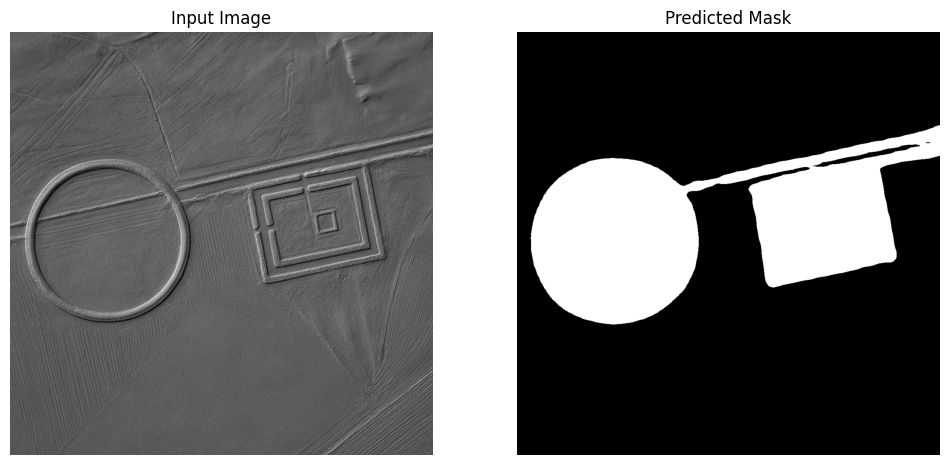

In [ ]:
# Import required libraries
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np
import torch

# Set device to GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Path of the test image stored in Google Drive
test_image_path = "/content/drive/MyDrive/sample_images/009.png"  # Change this to your own path if needed

# Load the image and convert to RGB format
pil_image = Image.open(test_image_path).convert("RGB")

# Convert image to tensor
transform = transforms.Compose([
    transforms.ToTensor(),
])
input_tensor = transform(pil_image).unsqueeze(0).to(device)  # Add batch dimension and move to device

# Predict the mask using the trained model
with torch.no_grad():
    output = model(input_tensor)['out']
    pred_mask = torch.sigmoid(output).squeeze().cpu().numpy()  # Apply sigmoid and convert to numpy
    pred_mask_bin = (pred_mask > 0.5).astype(np.uint8)  # Convert to binary mask (0 or 1)

# Show original image and predicted mask side by side
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title("Input Image")
plt.imshow(pil_image)
plt.axis('off')

plt.subplot(1,2,2)
plt.title("Predicted Mask")
plt.imshow(pred_mask_bin, cmap='gray')
plt.axis('off')

plt.show()

In [ ]:
# Save the trained model to a file in Google Drive
save_path = "/content/drive/MyDrive/best_model_DeepLabv3+_20_Epochs.pth"  # Set your folder path and filename
torch.save(model.state_dict(), save_path)
print(f"Model saved to {save_path}")

Model saved to /content/drive/MyDrive/best_model_DeepLabv3+_20_Epochs.pth
